In [ ]:
# 打开input.txt文本并读取
with open("input.txt", "r", encoding="utf-8") as file:  
    text = file.read()
chars = sorted(list(set(text)))
vocab_size = len(chars)  # 词表长度
print("Vocab size:", vocab_size)
print(''.join(chars))

Vocab size: 65

 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz


In [3]:
# str转index：stoi / index转str: itos
stoi = {ch:i for i,ch in enumerate(chars)}
itos = {i:ch for i,ch in enumerate(chars)}

# encode编码(str转换为对应index) / decode解码（index转换为对应str）   (`lambda` 用来创建简短、一次性的匿名函数)
encode = lambda s : [stoi[c] for c in s]
decode = lambda i : ''.join([itos[x] for x in i])

print(encode("hii, there"))
print(decode(encode("hii, there")))

[46, 47, 47, 6, 1, 58, 46, 43, 56, 43]
hii, there


In [4]:
import torch
# 转换成张量tensor，也就是gpt是如何看这些字符串内容的
data = torch.tensor(encode(text), dtype = torch.long)
print(data.shape, data.dtype)
print(data[:10]) 

torch.Size([1115394]) torch.int64
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47])


In [5]:
# 切分数据集
# 设置block_size：模型一次最多能 “看到” 的上下文 token 数量，也叫上下文窗口长度 / 序列长度
n = int(0.9*len(data)) 
train_data = data[:n]  # 训练集
val_data   = data[n:]  # 验证集

block_size = 8  # 模型最多拿前面 8 个 token，去预测下 1 个 token
train_data = data[:block_size + 1]
print(train_data)

x = train_data[:block_size]     # x = 上下文（输入给模型的 token 序列）
y = train_data[1:block_size+1]  # y = 要预测的目标 token 序列
for t in range(block_size):
    context = x[:t+1]
    target = y[t]
    print(f"when input is {context} the target: {target}")


tensor([18, 47, 56, 57, 58,  1, 15, 47, 58])
when input is tensor([18]) the target: 47
when input is tensor([18, 47]) the target: 56
when input is tensor([18, 47, 56]) the target: 57
when input is tensor([18, 47, 56, 57]) the target: 58
when input is tensor([18, 47, 56, 57, 58]) the target: 1
when input is tensor([18, 47, 56, 57, 58,  1]) the target: 15
when input is tensor([18, 47, 56, 57, 58,  1, 15]) the target: 47
when input is tensor([18, 47, 56, 57, 58,  1, 15, 47]) the target: 58


In [8]:
torch.manual_seed(1337)
batch_size = 4  # 批次，一次训练有多少个窗口
block_size = 8

# 从已有的文本数据中随机抽取若干段连续的 token，构造 GPT 训练需要的输入 x 和正确答案 y。
def get_batch(split):

    # split是一个字符串标记，用来告诉get_batch函数：从训练集还是验证集里面采样batch
    data = train_data if split == 'train' else val_data

    # 随机生成起始索引ix，也就是batch_size个窗口起始索引组成的一个张量（torch.randint的用法）
    ix = torch.randint(len(data) - block_size, (batch_size,))  # 张量维度取决于元组数的个数

    # 把每个索引开始的张量组合升维成 batch_size*block_size 大小的张量矩阵（torch.stack和torch.cat的区别）
    x = torch.stack([data[i:i+block_size] for i in ix])

    # 原理同x，不过是生成要预测的token序列
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])

    return x, y

xb, yb = get_batch('train')  # 一个 batch 版本的 x、y
print('input:')
print(xb.shape)
print(xb)
print('target:')
print(yb.shape)
print(yb)
print()
for b in range(batch_size):
    for t in range(block_size):
        context = xb[b, :t+1]
        target = yb[b,t]
        print(f"when input is {context.tolist()} the target: {target}")
# context.tolist()张量转列表


input:
torch.Size([4, 8])
tensor([[18, 47, 56, 57, 58,  1, 15, 47],
        [18, 47, 56, 57, 58,  1, 15, 47],
        [18, 47, 56, 57, 58,  1, 15, 47],
        [18, 47, 56, 57, 58,  1, 15, 47]])
target:
torch.Size([4, 8])
tensor([[47, 56, 57, 58,  1, 15, 47, 58],
        [47, 56, 57, 58,  1, 15, 47, 58],
        [47, 56, 57, 58,  1, 15, 47, 58],
        [47, 56, 57, 58,  1, 15, 47, 58]])

when input is [18] the target: 47
when input is [18, 47] the target: 56
when input is [18, 47, 56] the target: 57
when input is [18, 47, 56, 57] the target: 58
when input is [18, 47, 56, 57, 58] the target: 1
when input is [18, 47, 56, 57, 58, 1] the target: 15
when input is [18, 47, 56, 57, 58, 1, 15] the target: 47
when input is [18, 47, 56, 57, 58, 1, 15, 47] the target: 58
when input is [18] the target: 47
when input is [18, 47] the target: 56
when input is [18, 47, 56] the target: 57
when input is [18, 47, 56, 57] the target: 58
when input is [18, 47, 56, 57, 58] the target: 1
when input is [18, 

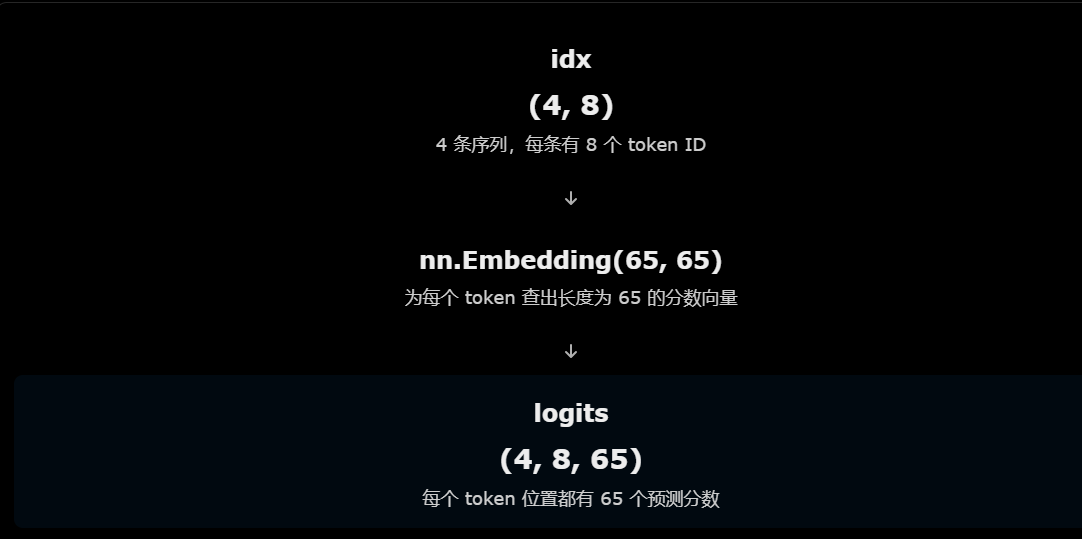

In [36]:
import torch
import torch.nn as nn                 # nn：用于定义神经网络结构
from torch.nn import functional as F  # F：调用激活函数、损失函数
torch.manual_seed(1337)

# 二元语法 Bigram 语言模型：最简单的语言模型Bigram Language Model
class BigramLanguageModel(nn.Module):  # 继承 nn.Module（PyTorch 所有标准神经网络模型的基础类）

    def __init__(self, vocab_size):
        super().__init__()  # super()代表父类nn.Module，调用父类nn.Module的初始化函数
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)
        # embedding的作用：将孤立的token嵌入到一个高维向量空间，向量空间里的距离就代表语义相似度
        # 其内部会创建一个可学习的权重矩阵,每一行表示某个当前 token 对下一个 token 的预测分数
        """
        nn.Embedding(num_embeddings, embedding_dim)
        num_embeddings：有多少个不同的token
        embedding_dim：每一行向量的长度（向量有多少个数字），也就是嵌入向量的维度
        """

    # 预测和计算损失
    def forward(self, idx, target = None):
        # 调用 Embedding 层自带的 forward
        logits = self.token_embedding_table(idx)   # logits是(B,T,C)

        # B = batch_size：一批有多少条文本序列
        # T = block_size：每条序列包含多少个 token
        # C = vocab_size：对于每个位置，模型都需要给词表中的每种 token 一个预测分数
        B, T, C = logits.shape
        if target is not None:  # 训练分支：有标签，计算loss（不传入target就不会执行这段）
            logits = logits.view(B*T, C)            # logits：模型认为每个答案分别有多大可能性
            target = target.view(B*T)               # targets：告诉模型哪个答案才是正确的
            loss = F.cross_entropy(logits, target)  # cross_entropy平均交叉熵损失
        else:  # 推理/生成分支：没有标签，不计算loss，loss=None
            loss = None
        return logits, loss

    # 利用模型的预测结果：预测下一个 token → 选择一个 token → 加入序列 → 再次预测
    def generate(self, idx, max_new_tokens):  # 文本生成函数 idx(B, T)
        for _ in range(max_new_tokens):

            # 文本生成没有标准答案，只关心下一个token，所以不用传target
            logits, loss = self(idx) 

            # 我们只需要预测当前序列往后新增的那 1 个token，前面位置已经是已知的历史，不需要再预测。 
            logits = logits[:, -1, :]  # (B, T, C) → (B, C)

            # dim 表示沿着张量的哪个维度进行计算，每个样本的 C 个 token 概率相加等于 1
            probs = F.softmax(logits, dim = -1)

            # torch.multinomial()根据概率抽样，probs不同token概率，取一个token（并不总是选概率最高的 token）
            idx_next = torch.multinomial(probs, num_samples = 1)

            # 在T这个维度上进行拼接 (B, T)→ (B, T+1)
            idx = torch.cat((idx, idx_next), dim = 1)

        return idx

m = BigramLanguageModel(vocab_size)
logits, loss = m(xb, yb)
print(logits.shape)
print(loss)

idx = torch.zeros((1, 1), dtype=torch.long)
print(decode(m.generate(idx, max_new_tokens=100)[0].tolist()))

torch.Size([256, 65])
tensor(4.4032, grad_fn=<NllLossBackward0>)

SKIcLT;AcELMoTbvZv C?nq-QE33:CJqkOKH-q;:la!oiywkHjgChzbQ?u!3bLIgwevmyFJGUGp
wnYWmnxKWWev-tDqXErVKLgJ


In [43]:
 # 建立优化器optimizer，m是一个继承自 nn.Module 的对象，可以调用m.parameters()
optimizer = torch.optim.AdamW(m.parameters(), lr=1e-3)  # 选取AdamW优化器

batch_size = 32
for steps in range(1000):

    # 向前传播
    xb, yb = get_batch('train')
    logits, loss = m(xb, yb)

    # 清除优化器管理的参数在上一轮反向传播中积累的梯度
    # True：会将已有梯度置为 None / False：对已有梯度执行清零
    optimizer.zero_grad(set_to_none=True)

    # 反向传播计算梯度，利用链式法则计算损失对各个可训练参数的梯度
    # backward() 只负责计算梯度，并将梯度存储到参数的 .grad 属性中，不会自动改变参数数值
    loss.backward()  # Tensor 对象的方法，不属于optimizer

    # 利用优化算法（这里是 AdamW）和已有梯度更新参数
    optimizer.step()

print(loss.item())

0.5119771361351013


In [45]:
idx = torch.zeros((1, 1), dtype=torch.long)
print(decode(m.generate(idx, max_new_tokens=400)[0].tolist()))


R:Cirst CJBit Cxj.?wbt Cd,q-dzO
C-w3d$stjU3BT:a
VyvHzCd!
&k.ZFirb
oBGd'-G&yD.Zay;QGRh
R:Cit Cirst Cirst CpUt Cirstp$
SVTo'OXEJvbH.stjrst Cit :vEstxUD,itRTsr&ZOdqU'q-OlyJkzLTSXE!h3:Cit Cirst Cirst CitWNLUDJsrst CirstSlyYDn CK$NgCirs!p
?3CitDst CG,irst CivHFirscNXqHZYSGvzLO'z,it C'KuDy3yEnPlyQbRmJANXla
RDGYtRt Ch$WSVcjN
Vstt CM,OT:Cir; CitUq-P CirJIcHRirsXst?gCKc Cit Ciyx
pUEKSPgR Cit CDM$E-wbit Cit
